- <font size="3">Arrays</font>
- <font size="3">Visualization</font>
- <font size="3">Timing</font>
- <font size="3">Quick fits</font>
- <font size="3">Root finding</font>

## Preamble

In [2]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rcdefaults()

plt.rc('font',**{'family':'serif','serif':['Times']})
plt.rc('text', usetex=True)

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=BIGGER_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title


%matplotlib inline

## NumPy arrays

In [3]:
plist = [1,2,3,4,5,6,7,8,9]

# conversion
narr = np.array(plist)

print(narr)
print(narr.shape)

# reshaping
narr_2d = narr.reshape(3,3)
print(narr_2d)
print(narr_2d.shape)

[1 2 3 4 5 6 7 8 9]
(9,)
[[1 2 3]
 [4 5 6]
 [7 8 9]]
(3, 3)


In [4]:
# generating an array: linear space
np.linspace(1,2,10)

array([1.        , 1.11111111, 1.22222222, 1.33333333, 1.44444444,
       1.55555556, 1.66666667, 1.77777778, 1.88888889, 2.        ])

In [5]:
# generating an array: log space
np.logspace(1,2,10)

array([ 10.        ,  12.91549665,  16.68100537,  21.5443469 ,
        27.82559402,  35.93813664,  46.41588834,  59.94842503,
        77.42636827, 100.        ])

In [6]:
# slicing 
log_arr = np.logspace(1,2,10)
print(log_arr[2:8:2])

[16.68100537 27.82559402 46.41588834]


In [7]:
# elementwise operations

x = np.linspace(-3,3,10)
y = x**2

print(x)
print(y)

[-3.         -2.33333333 -1.66666667 -1.         -0.33333333  0.33333333
  1.          1.66666667  2.33333333  3.        ]
[9.         5.44444444 2.77777778 1.         0.11111111 0.11111111
 1.         2.77777778 5.44444444 9.        ]


In [8]:
# conditions

cond = x>0
x_plus = x[cond]

print(cond)
print(x_plus)

[False False False False False  True  True  True  True  True]
[0.33333333 1.         1.66666667 2.33333333 3.        ]


## Visualization

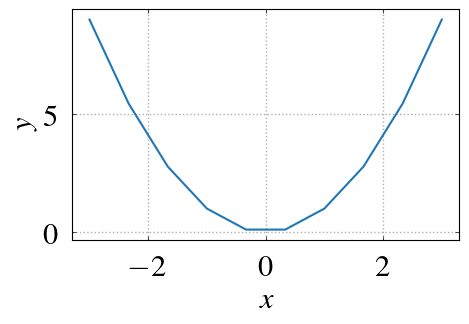

In [9]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

# x = np.linspace(-3,3,100)
# y = x**2

ax.plot(x,y)
#ax.plot(x[cond],y[cond])
#ax.scatter(x,y)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

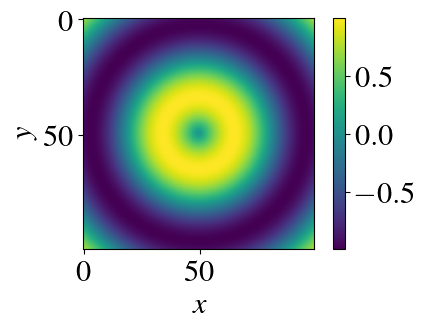

In [10]:
x = np.linspace(-5,5,100)
y = np.linspace(-5,5,100)

x,y = np.meshgrid(x,y)

z = np.sin(np.sqrt(x**2 + y**2))

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

cax = ax.imshow(z)

fig.colorbar(cax, ax=ax)

ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

### Log-scale plots

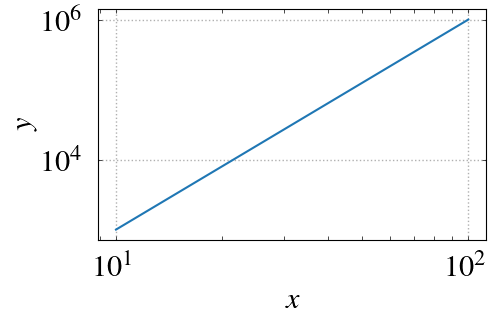

In [11]:
# power law

x = np.logspace(1, 2, 100)
y = x**3

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

ax.loglog(x,y)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

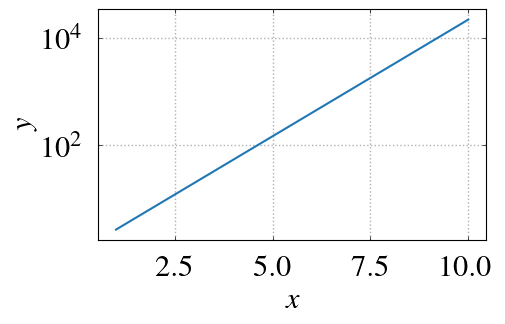

In [12]:
# exponential

x = np.logspace(0, 1, 100)
y = np.exp(x)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

ax.semilogy(x,y)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

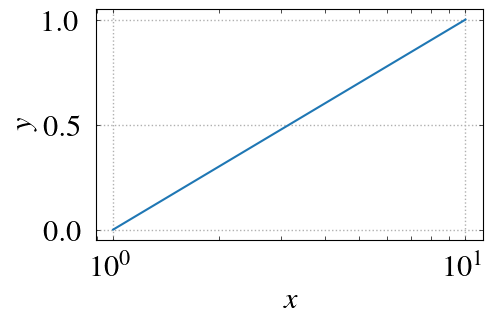

In [13]:
# logarithmic

x = np.logspace(0, 1, 100)
y = np.log10(x)

fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

ax.semilogx(x,y)

ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('$x$')
ax.set_ylabel('$y$');

### Histograms

In [44]:
# generate random samples

sample_size = 10

sample_uniform = np.random.random(sample_size)
sample_gaussian = np.random.randn(sample_size)

print(sample_uniform)
print(sample_gaussian)

[0.94163771 0.44562705 0.66995763 0.9243307  0.61942347 0.32258573
 0.31947631 0.29145669 0.95741742 0.40595834]
[ 1.40772776 -1.68769633  1.47123399  1.63646291 -0.46139494 -0.20136227
 -0.57181673 -0.60329911 -1.33938922 -1.68965292]


In [55]:
# numpy histograms

all_counts = []

np.histogram(sample_uniform)

# np.mean
# np.std

(array([3, 1, 1, 0, 1, 1, 0, 0, 0, 3]),
 array([0.29145669, 0.35805276, 0.42464883, 0.49124491, 0.55784098,
        0.62443705, 0.69103313, 0.7576292 , 0.82422528, 0.89082135,
        0.95741742]))

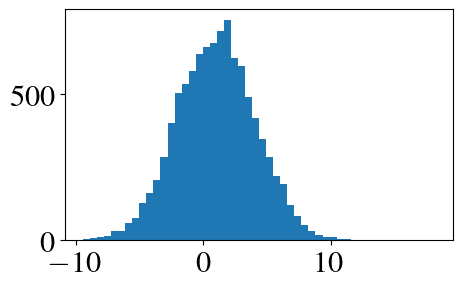

In [15]:
# pyplot histograms

mu = 1
sigma = 3
n_samples = 10000

samples = sigma * np.random.randn(n_samples) + mu


fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

ax.hist(samples, bins=50);

<u>EXERCISE</u>

1. Generate the histogram a few times in a row. How do the bin counts change?
2. Try to draw on top the plot of the Gaussian distribution function (see the Prelimiinaries notebook). Why doesn't it follow the histogram?
3. Plot the histogram adding keyword `density` (i.e. `ax.hist(..., density=True)`). What has changed? Has it fixed the issue with the distribution function?

## Timing

In [16]:
%%time

N = 1000000

x = np.logspace(1, 2, N)
y = x**3
#y = [each_x**3 for each_x in x]

CPU times: user 40.6 ms, sys: 68.8 ms, total: 109 ms
Wall time: 39.4 ms


In [17]:
from time import time

for N in np.logspace(1,6,10):
    
    x = np.logspace(1, 2, int(N))
    
    start = time()
    y = x**3
    #y = [each_x**3 for each_x in x]
    print('{}'.format(time()-start))    

8.106231689453125e-06
4.5299530029296875e-06
5.0067901611328125e-06
1.0967254638671875e-05
0.0001556873321533203
0.00015592575073242188
0.0003788471221923828
0.001356363296508789
0.004950284957885742
0.01729893684387207


In [18]:
times_np = []

sizes = np.logspace(1,8,10)

for N in sizes:
    
    x = np.logspace(1, 2, int(N))
    
    start = time()
    y = x**3
    times_np.append(time()-start)
    
times_np = np.array(times_np)

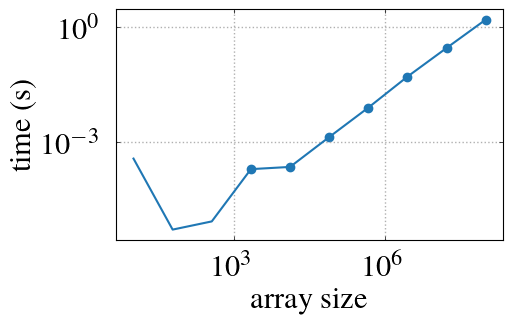

In [19]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

ax.loglog(sizes, times_np)

cond = sizes>1e+3
ax.scatter(sizes[cond], times_np[cond])


ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('array size')
ax.set_ylabel('time (s)');

<u>EXERCISE</u>

Experiment with other ways to compute $x^3$ elementwise:
- list comperehension (i.e. generating a list elementwise, for example, `[each_x for each_x in x]`);
- mapping (i.e. applying `map(..., ..., ...)` to the lists of elements and powers);
- introducing a condition, both in the numpy way `x[cond]` and with an `if` statement;

How do they compare in terms of time?

## Quick fit

In [20]:
from scipy.optimize import curve_fit

def f_model(log_size, m,b):
    return m*log_size + b

xdata = np.log10(sizes[cond])
ydata = np.log10(times_np[cond])

pars,_ = curve_fit(f_model, xdata, ydata)

pars

array([ 0.896043  , -7.06541652])

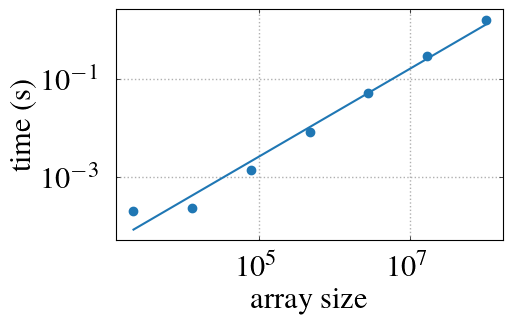

In [21]:
fig,ax = plt.subplots(ncols=1, nrows=1, figsize=(5,3))

ax.set_xscale('log')
ax.set_yscale('log')

ax.scatter(10**xdata, 10**ydata)
ax.loglog(10**xdata, 10**f_model(xdata, *pars))

# cond = sizes>1e+3
# ax.loglog(sizes[cond], times_np[cond])


ax.grid(True,linestyle=':',linewidth='1.')
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params('both',length=3,width=0.5,which='both',direction = 'in',pad=10)


ax.set_xlabel('array size')
ax.set_ylabel('time (s)');

<u>EXERCISE</u>

Experiment with different operations on $x$ ($x$ can be a different array of different shape). How does the computation time scale with the size for them? 

Ideas for the operations:
- computing the inverse of an $N\times N$ matrix, `np.linalg.inv(...)`;
- computing the fast Fourier transform (FFT) of a 1D array, `np.fft.fft(...)`. Don't worry if you haven't heard of Fourier transforms before, we will talk about them next time. For the purpose of this exercise, it is just a function that can take a 1D array as an input and "spits out" a complex 1D array of the same size.

## Root finding

One of the sampling techniques we will be talking about next time requires finding the real root of a monotonically increasing function. 

### Bisection method

The bisection method works well (is guaranteed to converge) for such functions.

<u>Example</u>.

Consider $g(x)=x^3 - 1$. This function is monotically increasing on $\mathbb{R}$. In addition, $g(2)>0$ and $g(-1)<0$. Therefore, it has root on $(-1,2)$.

In [22]:
def g(x):
    return x**3 - 1

a = -1
b = 2

n_iter = 10

for i in range(n_iter):
    
    mid_pt = (a+b)/2
    if g(mid_pt)>0:
        b = mid_pt
    else:
        a = mid_pt
        
    print(mid_pt)

0.5
1.25
0.875
1.0625
0.96875
1.015625
0.9921875
1.00390625
0.998046875
1.0009765625


In [23]:
# specifying tolerance

atol = 1e-8
err = 1

while err > atol:
    
    mid_pt = (a+b)/2
    
    if g(mid_pt)>0:
        b = mid_pt
    else:
        a = mid_pt
        
    err = abs(g(mid_pt))

root = mid_pt
print(root)

0.9999999981373549


### Using `scipy` for root finding

In [24]:
from scipy.optimize import fsolve

root_estimate = 10

fsolve(g, root_estimate)

array([1.])

## Home exercises

<font size="3">(completing one is required; completing more is recommended)</font>

#### 1. Variation of the counts due to finite size of the sample

- fix the number of bins or the bins themselves;
- generate histograms for a Gaussian distribution multiple times and record the numbers of counts (you can use `np.histogram(...)` instead of `ax.hist(...)` to avoid the need to plot each time);
- compute the means for the counts in each bin, `np.mean(...)`;
- compute the r.m.s. deviation, `np.std(...)` (this is a measure of deviation from the mean);
- plot a random histogram with the mean histogram on top;
- indicate the r.m.s. devitation for each bin;
- make sure to properly label the plot ($x$/$y$ labels, legend, etc.);

#### 2. Fluctuations of the counts in a bin

- fix a bin (choose its edges);
- choose a sample size;
- generate multiple samples of that size for a Gaussian distribution recording each time the counts for the bin;
- compute the mean and the r.m.s. deviation for the counts (`np.mean(...)` and `np.std(...)`);
- repeat a few times increasing the sample size;
- plot the means against the r.m.s. deviations (you may need a log-log plot);
- does it look like a power law? if yes, what is the slope?
- make sure to properly label the plot ($x$/$y$ labels, legend, etc.);

#### 3. Timing the root finding

- pick a monotonically increasing function;
- time the root finding (bisection) changing the relative tolerance (for two consecutive iterations $x_{i+1}$ and $x_i$, it is given by $|x_{i+1}/x_i-1|$);
- plot that timing; does it look like a power law? if yes, what is the slope?
- make a similar plot using `fsolve` (the keyword for relative tolerance is `xtol`); how do the two plots compare?
- experiment with the plots changing the function, initial estimate for `fsolve`, the length of the interval with the root;
- describe your findings;
- make sure to properly label the plot ($x$/$y$ labels, legend, etc.);